# Model Training: Logistic Regression, SVM, Random Forest
Target: `ICU` (yes=1 / no=0). Rows without an ICU label are dropped. Features: Age, Gender + the median significant genes (same set as Model Training 1).

In [1]:
import os, json, joblib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, roc_curve, auc, ConfusionMatrixDisplay

def evaluate(name, model, X_te, y_te):
    y_pred = model.predict(X_te)
    y_score = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_te)
    acc = accuracy_score(y_te, y_pred)
    fpr, tpr, _ = roc_curve(y_te, y_score)
    roc_auc = auc(fpr, tpr)
    print(f"{name} -> Accuracy: {acc:.4f} | Precision: {precision_score(y_te, y_pred):.4f} | "
          f"Recall: {recall_score(y_te, y_pred):.4f} | F1: {f1_score(y_te, y_pred):.4f} | AUC: {roc_auc:.4f}")
    print(classification_report(y_te, y_pred, target_names=["No ICU", "ICU"], digits=4))
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
    ConfusionMatrixDisplay.from_predictions(y_te, y_pred, display_labels=["No ICU", "ICU"], cmap="Blues", ax=ax[0])
    ax[0].set_title(f"{name} - Confusion Matrix (Acc={acc:.3f})")
    ax[1].plot(fpr, tpr, lw=2, label=f"AUC = {roc_auc:.3f}")
    ax[1].plot([0, 1], [0, 1], "k--", lw=1)
    ax[1].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title=f"{name} - ROC Curve")
    ax[1].legend(loc="lower right")
    plt.tight_layout(); plt.show()

SAVE_DIR = "saved_models_2"
os.makedirs(SAVE_DIR, exist_ok=True)


In [2]:
# Import data
df = pd.read_csv("Final_Dataset_AIBD.csv", index_col=0, low_memory=False)
df = df.drop(columns=["Unnamed: 0"])          # sample ID column
df = df.dropna(subset=["ICU"]).reset_index(drop=True)   # keep labelled samples only
y = (df["ICU"] == "yes").astype(int)
# Same gene set as Model Training 1 (median significant genes) + clinical covariates (Age, Gender)
with open("median_significant_genes.json") as f:
    sig = json.load(f)
genes = [g for g in dict.fromkeys(sum(sig.values(), [])) if g in df.columns]
print("Number of median significant genes used:", len(genes))
X = pd.get_dummies(df[["Age", "Gender"] + genes], columns=["Gender"], dtype=float)
print("Shape:", X.shape, "| class counts:", y.value_counts().to_dict())

# Split first, then normalize (scaler fit on train only to avoid leakage)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=42)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)
print("Train:", X_train_s.shape, "Test:", X_test_s.shape)
joblib.dump(scaler, f"{SAVE_DIR}/scaler.joblib")
json.dump(list(X.columns), open(f"{SAVE_DIR}/features.json", "w"))


Number of median significant genes used: 12720
Shape: (100, 12723) | class counts: {0: 50, 1: 50}


Train: (75, 12723) Test: (25, 12723)


## Logistic Regression

Logistic Regression -> Accuracy: 0.9200 | Precision: 1.0000 | Recall: 0.8333 | F1: 0.9091 | AUC: 0.9615
              precision    recall  f1-score   support

      No ICU     0.8667    1.0000    0.9286        13
         ICU     1.0000    0.8333    0.9091        12

    accuracy                         0.9200        25
   macro avg     0.9333    0.9167    0.9188        25
weighted avg     0.9307    0.9200    0.9192        25



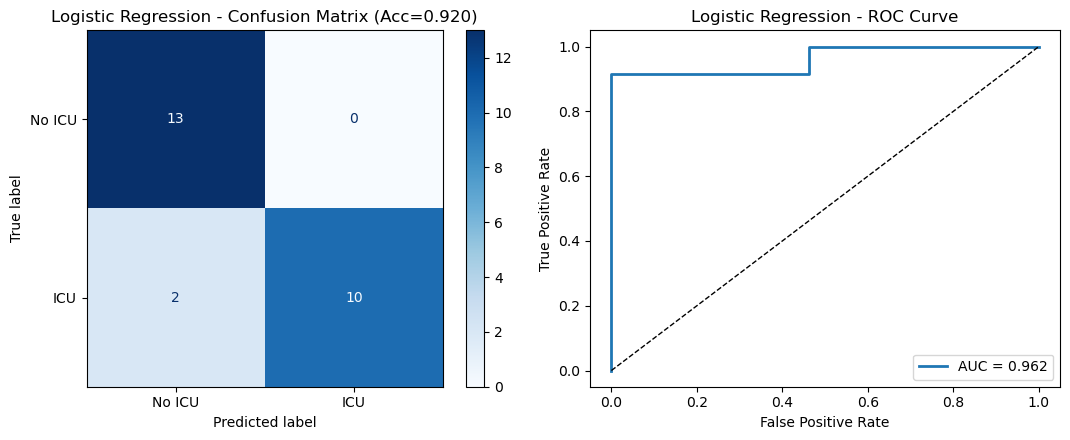

Saved -> saved_models_2/logistic_regression.joblib


In [3]:
lr = LogisticRegression(max_iter=5000, random_state=42)
lr.fit(X_train_s, y_train)
evaluate("Logistic Regression", lr, X_test_s, y_test)
joblib.dump(lr, f"{SAVE_DIR}/logistic_regression.joblib")
print("Saved ->", f"{SAVE_DIR}/logistic_regression.joblib")


## SVM

SVM -> Accuracy: 0.8400 | Precision: 0.8333 | Recall: 0.8333 | F1: 0.8333 | AUC: 0.8974
              precision    recall  f1-score   support

      No ICU     0.8462    0.8462    0.8462        13
         ICU     0.8333    0.8333    0.8333        12

    accuracy                         0.8400        25
   macro avg     0.8397    0.8397    0.8397        25
weighted avg     0.8400    0.8400    0.8400        25



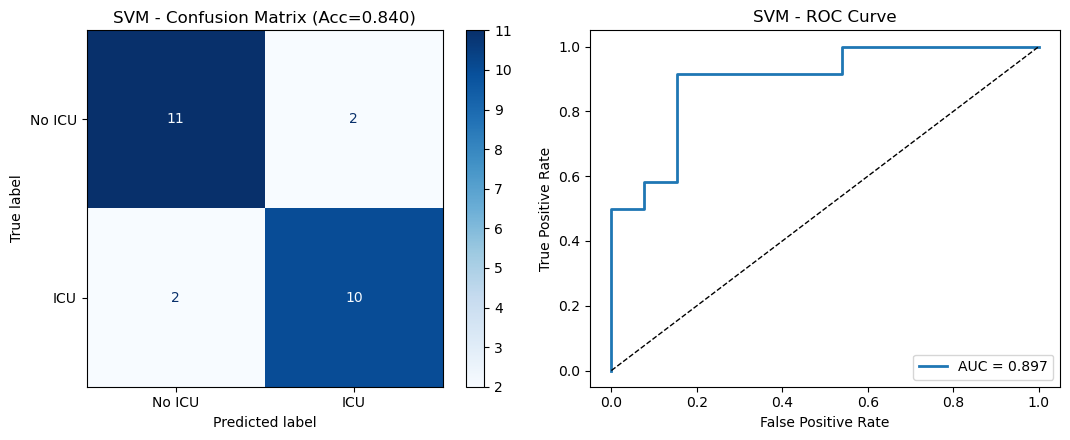

Saved -> saved_models_2/svm.joblib


In [4]:
svm = SVC(kernel="rbf", probability=True, random_state=42)
svm.fit(X_train_s, y_train)
evaluate("SVM", svm, X_test_s, y_test)
joblib.dump(svm, f"{SAVE_DIR}/svm.joblib")
print("Saved ->", f"{SAVE_DIR}/svm.joblib")


## Random Forest

Random Forest -> Accuracy: 0.7600 | Precision: 0.8000 | Recall: 0.6667 | F1: 0.7273 | AUC: 0.8718
              precision    recall  f1-score   support

      No ICU     0.7333    0.8462    0.7857        13
         ICU     0.8000    0.6667    0.7273        12

    accuracy                         0.7600        25
   macro avg     0.7667    0.7564    0.7565        25
weighted avg     0.7653    0.7600    0.7577        25



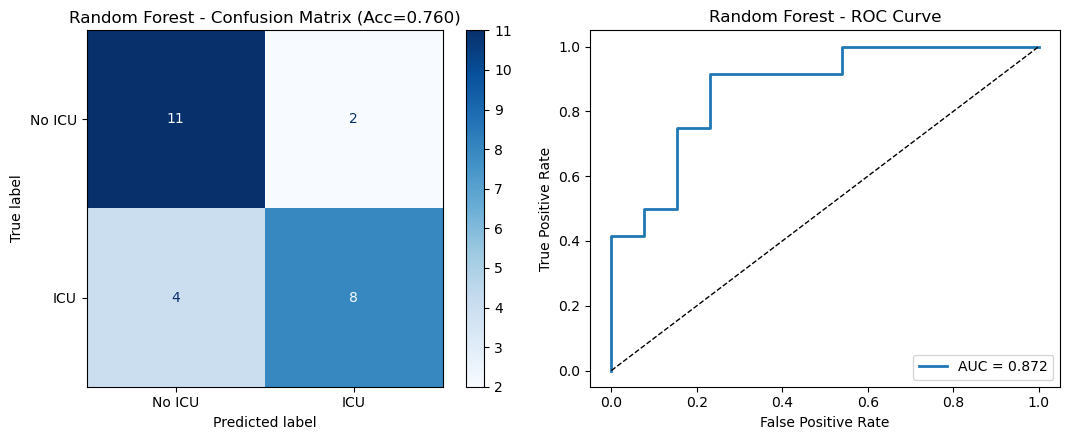

Saved -> saved_models_2/random_forest.joblib


In [5]:
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)
rf.fit(X_train_s, y_train)
evaluate("Random Forest", rf, X_test_s, y_test)
joblib.dump(rf, f"{SAVE_DIR}/random_forest.joblib")
print("Saved ->", f"{SAVE_DIR}/random_forest.joblib")
